# Comparaison des modèles — Prévision de la demande de vélos

Ce notebook compare les cinq approches demandées sur le jeu horaire : Régression linéaire, Ridge, Arbre de régression, Random Forest et Gradient Boosting. Il utilise une séparation chronologique train/test (80 % / 20 %) et une validation TimeSeriesSplit sur l'entraînement pour le réglage des hyperparamètres.

Les modèles sont comparés avec MAE, RMSE et R² sur la période de test. Le test reste isolé pendant le réglage. Les variables casual et registered sont exclues car leur somme est cnt (fuite de cible); instant est un index et dteday brute est utilisée uniquement pour trier chronologiquement.

## 1. Imports et chargement des données

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
DATA_FILE = Path('bike_sharing_dataset/hour.csv')  # remplacer par day.csv pour les données journalières
TARGET = 'cnt'
df = pd.read_csv(DATA_FILE, parse_dates=['dteday']).sort_values(['dteday'] + (['hr'] if 'hr' in pd.read_csv(DATA_FILE, nrows=0).columns else [])).reset_index(drop=True)
print('Dimensions :', df.shape)
print('Période :', df.dteday.min(), '→', df.dteday.max())
display(df.head())

Dimensions : (17379, 17)
Période : 2011-01-01 00:00:00 → 2012-12-31 00:00:00


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 2. Définition de X et y, puis séparation chronologique

Les variables catégorielles sont encodées en one-hot. Les variables numériques sont standardisées, ce qui est important pour la Régression linéaire et Ridge. Toutes les transformations sont dans le pipeline et sont donc ajustées uniquement sur les plis d'entraînement.

In [2]:
excluded = {TARGET, 'casual', 'registered', 'instant', 'dteday'}
feature_cols = [c for c in df.columns if c not in excluded]
X = df[feature_cols].copy()
y = df[TARGET].copy()
categorical_features = [c for c in ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit'] if c in X.columns]
numeric_features = [c for c in X.columns if c not in categorical_features]
split_idx = int(0.8 * len(df))
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
print('Variables utilisées :', feature_cols)
print('Catégorielles :', categorical_features)
print('Numériques :', numeric_features)
print(f'Train : {len(X_train):,} observations | Test : {len(X_test):,} observations')
print('Fin train :', df.dteday.iloc[split_idx - 1], '| début test :', df.dteday.iloc[split_idx])

Variables utilisées : ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
Catégorielles : ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit']
Numériques : ['temp', 'atemp', 'hum', 'windspeed']
Train : 13,903 observations | Test : 3,476 observations
Fin train : 2012-08-07 00:00:00 | début test : 2012-08-07 00:00:00


## 3. Exploration de la demande sur le train

Ces graphiques décrivent uniquement la période d'entraînement. Le test chronologique reste réservé à l'évaluation finale.

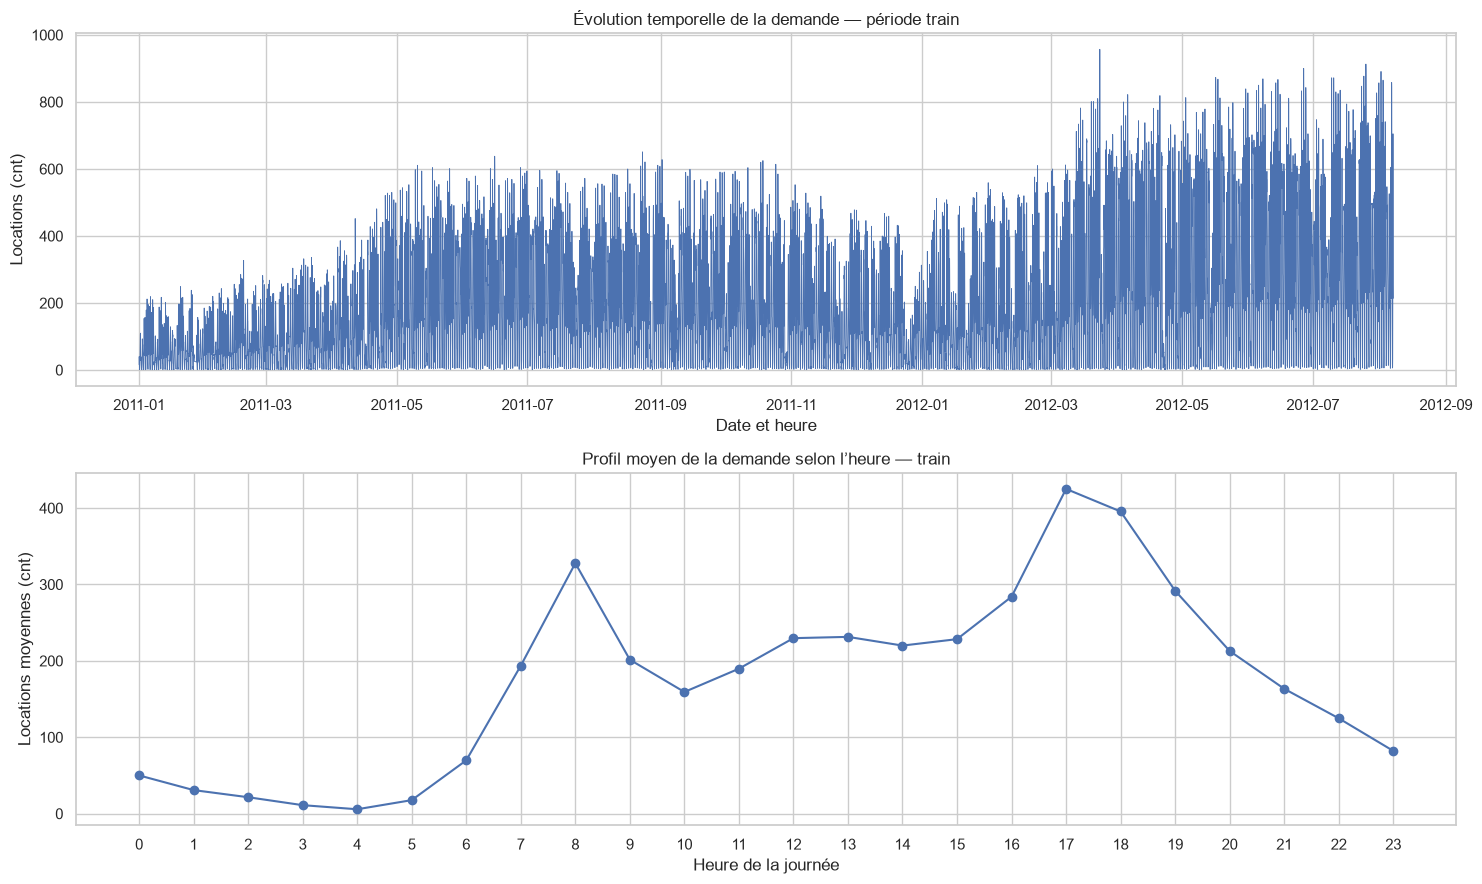

In [3]:
train_df = df.iloc[:split_idx].copy()
train_df['timestamp'] = train_df['dteday'] + pd.to_timedelta(train_df['hr'], unit='h')
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
axes[0].plot(train_df['timestamp'], train_df[TARGET], linewidth=0.6)
axes[0].set_title('Évolution temporelle de la demande — période train')
axes[0].set_xlabel('Date et heure'); axes[0].set_ylabel('Locations (cnt)')
hour_profile = train_df.groupby('hr')[TARGET].mean()
axes[1].plot(hour_profile.index, hour_profile.values, marker='o')
axes[1].set_xticks(range(24)); axes[1].set_title('Profil moyen de la demande selon l’heure — train')
axes[1].set_xlabel('Heure de la journée'); axes[1].set_ylabel('Locations moyennes (cnt)')
plt.tight_layout(); plt.show()

In [4]:
numeric_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('num', numeric_pipe, numeric_features), ('cat', categorical_pipe, categorical_features)])
cv = TimeSeriesSplit(n_splits=5)

## 3. Régression linéaire et Ridge

La Régression linéaire sert de référence sans réglage. Ridge est d'abord évaluée avec alpha=1 (référence), puis alpha est choisi par validation croisée temporelle en minimisant la RMSE.

In [5]:
linear_model = Pipeline([('prep', preprocessor), ('model', LinearRegression())])
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

ridge_baseline = Pipeline([('prep', preprocessor), ('model', Ridge(alpha=1.0))])
ridge_baseline.fit(X_train, y_train)
ridge_baseline_pred = ridge_baseline.predict(X_test)

ridge_pipe = Pipeline([('prep', preprocessor), ('model', Ridge())])
ridge_search = GridSearchCV(ridge_pipe, {'model__alpha': [0.01, 0.1, 1, 10, 100]}, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1, refit=True)
ridge_search.fit(X_train, y_train)
ridge_pred = ridge_search.predict(X_test)
print('Meilleur alpha Ridge :', ridge_search.best_params_['model__alpha'])
print('RMSE moyenne CV Ridge :', round(-ridge_search.best_score_, 3))

Meilleur alpha Ridge : 0.01
RMSE moyenne CV Ridge : 108.762


## 4. Arbre de régression

Le réglage porte sur max_depth. Une profondeur limitée contrôle la complexité de l'arbre et aide à réduire le surapprentissage.

In [6]:
tree_pipe = Pipeline([('prep', preprocessor), ('model', DecisionTreeRegressor(random_state=42))])
tree_search = GridSearchCV(tree_pipe, {'model__max_depth': [5, 10, 20, None]}, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1, refit=True)
tree_search.fit(X_train, y_train)
tree_pred = tree_search.predict(X_test)
print('Meilleurs paramètres arbre :', tree_search.best_params_)
print('RMSE moyenne CV arbre :', round(-tree_search.best_score_, 3))

Meilleurs paramètres arbre : {'model__max_depth': 20}
RMSE moyenne CV arbre : 113.084


## 5. Random Forest Regressor

Le nombre d'arbres (n_estimators) et la profondeur maximale (max_depth) sont choisis par validation croisée temporelle.

In [7]:
forest_pipe = Pipeline([('prep', preprocessor), ('model', RandomForestRegressor(random_state=42, n_jobs=1))])
forest_search = GridSearchCV(forest_pipe, {'model__n_estimators': [100, 200], 'model__max_depth': [10, 20, None]}, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1, refit=True)
forest_search.fit(X_train, y_train)
forest_pred = forest_search.predict(X_test)
print('Meilleurs paramètres Random Forest :', forest_search.best_params_)
print('RMSE moyenne CV Random Forest :', round(-forest_search.best_score_, 3))

Meilleurs paramètres Random Forest : {'model__max_depth': None, 'model__n_estimators': 100}
RMSE moyenne CV Random Forest : 88.582


## 6. Gradient Boosting Regressor

Le nombre d'arbres (n_estimators) et le taux d'apprentissage (learning_rate) sont réglés par validation croisée temporelle.

In [8]:
boost_pipe = Pipeline([('prep', preprocessor), ('model', GradientBoostingRegressor(random_state=42))])
boost_search = GridSearchCV(boost_pipe, {'model__n_estimators': [100, 200], 'model__learning_rate': [0.03, 0.1, 0.2]}, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1, refit=True)
boost_search.fit(X_train, y_train)
boost_pred = boost_search.predict(X_test)
print('Meilleurs paramètres Gradient Boosting :', boost_search.best_params_)
print('RMSE moyenne CV Gradient Boosting :', round(-boost_search.best_score_, 3))

Meilleurs paramètres Gradient Boosting : {'model__learning_rate': 0.2, 'model__n_estimators': 200}
RMSE moyenne CV Gradient Boosting : 81.325


## 7. Évaluation finale sur le test chronologique

In [ ]:
predictions = {
    'Régression linéaire (référence)': linear_pred,
    'Ridge (alpha=1, référence)': ridge_baseline_pred,
    'Ridge (alpha optimisé)': ridge_pred,
    'Arbre de régression': tree_pred,
    'Random Forest': forest_pred,
    'Gradient Boosting': boost_pred,
}
results = []
for name, pred in predictions.items():
    results.append({'Modèle': name, 'MAE': mean_absolute_error(y_test, pred), 'RMSE': np.sqrt(mean_squared_error(y_test, pred)), 'R²': r2_score(y_test, pred)})
results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
display(results_df.round(3))
best_name = results_df.iloc[0]['Modèle']
print('Meilleur modèle selon RMSE test :', best_name)
print('Meilleurs réglages :')
print('Ridge :', ridge_search.best_params_)
print('Arbre :', tree_search.best_params_)
print('Random Forest :', forest_search.best_params_)
print('Gradient Boosting :', boost_search.best_params_)

,Modèle,MAE,RMSE,R²
0,Random Forest,54.511,82.208,0.861
1,Gradient Boosting,63.692,90.518,0.831
2,Arbre de régression,64.504,98.409,0.801
3,Régression linéaire (référence),98.798,133.835,0.632
4,Ridge (alpha optimisé),98.819,133.846,0.631
5,"Ridge (alpha=1, référence)",98.868,133.907,0.631


Meilleur modèle selon RMSE test : Random Forest
Meilleurs réglages :
Ridge : {'model__alpha': 0.01}
Arbre : {'model__max_depth': 20}
Random Forest : {'model__max_depth': None, 'model__n_estimators': 100}
Gradient Boosting : {'model__learning_rate': 0.2, 'model__n_estimators': 200}


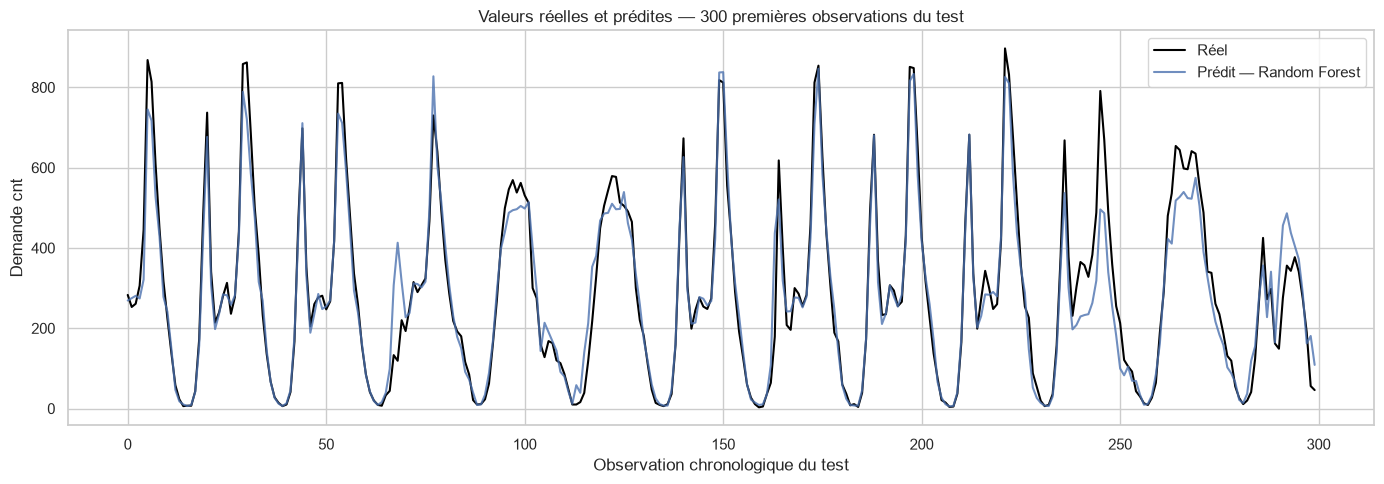

In [10]:
best_pred = predictions[best_name]
n = min(300, len(y_test))
plt.figure(figsize=(14, 5))
plt.plot(y_test.iloc[:n].to_numpy(), label='Réel', color='black')
plt.plot(best_pred[:n], label=f'Prédit — {best_name}', alpha=0.8)
plt.title(f'Valeurs réelles et prédites — {n} premières observations du test')
plt.xlabel('Observation chronologique du test'); plt.ylabel('Demande cnt'); plt.legend(); plt.tight_layout(); plt.show()

## 8. Comparaison des erreurs selon l’heure

On calcule pour chaque modèle la RMSE et l’erreur moyenne signée (prédit − réel) à chacune des 24 heures, uniquement sur le test. Une erreur moyenne positive indique une surestimation; une erreur négative, une sous-estimation.

,Modèle,Heure,RMSE,Erreur moyenne (prédit − réel),MAE
0,Régression linéaire (référence),0,71.93,50.51,61.52
1,Régression linéaire (référence),1,77.45,56.96,66.06
2,Régression linéaire (référence),2,78.46,63.75,67.61
3,Régression linéaire (référence),3,76.23,66.63,67.92
4,Régression linéaire (référence),4,75.31,67.01,68.56
...,...,...,...,...,...
139,Gradient Boosting,19,99.48,-37.42,82.00
140,Gradient Boosting,20,71.92,-23.78,59.34
141,Gradient Boosting,21,55.14,6.48,44.94
142,Gradient Boosting,22,43.85,8.88,34.60


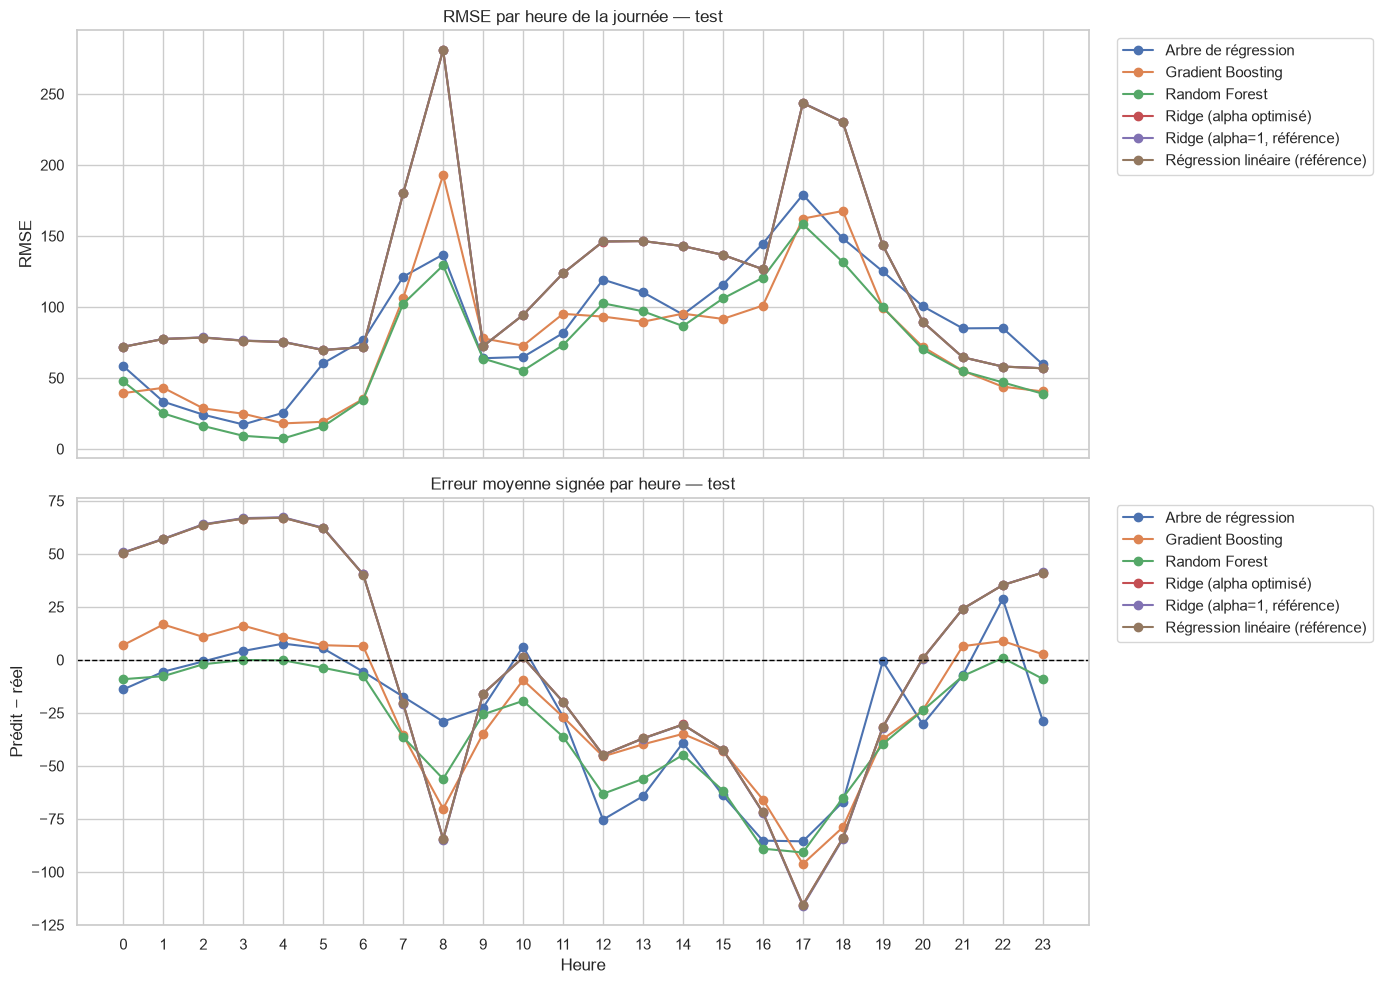

,Modèle,Heure,RMSE,Erreur moyenne (prédit − réel),MAE
103,Random Forest,7,102.22,-36.39,82.95
127,Gradient Boosting,7,106.27,-35.65,90.70
79,Arbre de régression,7,121.35,-17.35,81.96
7,Régression linéaire (référence),7,180.00,-20.54,168.69
55,Ridge (alpha optimisé),7,180.02,-20.51,168.72
31,"Ridge (alpha=1, référence)",7,180.04,-20.65,168.74
104,Random Forest,8,129.29,-56.12,101.59
80,Arbre de régression,8,136.97,-29.09,99.70
128,Gradient Boosting,8,192.83,-70.17,171.83
8,Régression linéaire (référence),8,280.94,-84.41,272.78


In [11]:
hourly_rows = []
for name, pred in predictions.items():
    detail = pd.DataFrame({'hr': X_test['hr'].to_numpy(), 'y_true': y_test.to_numpy(), 'y_pred': pred})
    detail['error'] = detail['y_pred'] - detail['y_true']
    for hr, group in detail.groupby('hr'):
        hourly_rows.append({'Modèle': name, 'Heure': int(hr), 'RMSE': np.sqrt(mean_squared_error(group['y_true'], group['y_pred'])), 'Erreur moyenne (prédit − réel)': group['error'].mean(), 'MAE': mean_absolute_error(group['y_true'], group['y_pred'])})
hourly_results = pd.DataFrame(hourly_rows)
display(hourly_results.round(2))

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
for name, group in hourly_results.groupby('Modèle'):
    group = group.sort_values('Heure')
    axes[0].plot(group['Heure'], group['RMSE'], marker='o', label=name)
    axes[1].plot(group['Heure'], group['Erreur moyenne (prédit − réel)'], marker='o', label=name)
axes[0].set_title('RMSE par heure de la journée — test'); axes[0].set_ylabel('RMSE')
axes[1].set_title('Erreur moyenne signée par heure — test'); axes[1].set_ylabel('Prédit − réel'); axes[1].set_xlabel('Heure')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
for ax in axes: ax.set_xticks(range(24)); ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()

rush_hours = [7, 8, 9, 16, 17, 18]
display(hourly_results[hourly_results['Heure'].isin(rush_hours)].sort_values(['Heure', 'RMSE']).round(2))

## 9. Conclusion à rédiger après exécution

Comparer d'abord la RMSE (plus petite = meilleure), puis MAE et R². Indiquer le meilleur modèle sur la période de test et les hyperparamètres retenus par validation croisée. Décrire les heures où la RMSE est la plus élevée et le signe du biais aux heures de pointe (7–9 h et 16–18 h).

Limite opérationnelle : les variables météo utilisées pour prévoir une période future doivent être disponibles à l'avance sous forme de prévisions météo. Si elles ne sont pas disponibles ou sont erronées, les performances observées ici peuvent être surestimées. Le test représente la période future réservée et ne doit pas servir à régler à nouveau les modèles.